# Lab 3 — Fraud Detection and Insurance Cost Prediction
**Echezona Oji | Student ID: 9078881**

In this lab, I used logistic regression to detect fraudulent transactions and linear regression to predict insurance costs. I used a **70/30 train–test split** and **random seed 42** for both tasks.

## Setup
My data sources were the assigned Kaggle datasets: [credit-card fraud](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) and [insurance costs](https://www.kaggle.com/datasets/mirichoi0218/insurance).

To rerun, keep the `data/` folder beside the notebook, install `requirements.txt`, and select **Restart Kernel and Run All**. The code records package versions and file hashes for reproducibility.

In [1]:
from pathlib import Path
import hashlib, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    PrecisionRecallDisplay, r2_score, mean_absolute_error, mean_squared_error)
from sklearn.exceptions import ConvergenceWarning
SEED = 42
DATA = Path('data')
RESULTS = Path('results'); RESULTS.mkdir(exist_ok=True)
pd.set_option('display.max_columns', 12)
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
print({'Python': platform.python_version(), 'pandas': pd.__version__,
       'numpy': np.__version__, 'scikit-learn': sklearn.__version__})
for name in ['creditcard.csv', 'insurance.csv']:
    print(name, 'SHA-256:', hashlib.sha256((DATA/name).read_bytes()).hexdigest())

{'Python': '3.12.10', 'pandas': '3.0.6', 'numpy': '2.4.6', 'scikit-learn': '1.8.0'}
creditcard.csv SHA-256: 76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89
insurance.csv SHA-256: 388eff679557d08ac19f463d025de5e0b4adc482537c8456d19934d78621fd47


## Part A — Credit-card fraud detection
### Inspect and clean
I predicted `Class` (0 = legitimate, 1 = fraud) using the remaining numeric columns. I checked missing values and removed exact duplicate rows before splitting to reduce train–test overlap. Without transaction IDs, I could not confirm whether every duplicate was an error. I retained unusual amounts because they could help identify fraud.

In [2]:
fraud_raw = pd.read_csv(DATA/'creditcard.csv')
print('Original dimensions:', fraud_raw.shape)
display(fraud_raw.head())
print('Missing values:', int(fraud_raw.isna().sum().sum()))
display(fraud_raw['Class'].value_counts().sort_index().rename('transactions').to_frame())
assert fraud_raw['Class'].isin([0, 1]).all()
assert np.isfinite(fraud_raw.to_numpy()).all()
assert fraud_raw['Amount'].ge(0).all()
print('Exact duplicate rows:', fraud_raw.duplicated().sum())
fraud = fraud_raw.drop_duplicates().copy()
print('Rows after removing exact duplicates:', len(fraud))
print('Fraud prevalence after deduplication:', f"{fraud['Class'].mean():.4%}")

Original dimensions: (284807, 31)


,Time,V1,V2,V3,V4,V5,...,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,...,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,...,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,...,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,...,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,...,-0.206010,0.502292,0.219422,0.215153,69.99,0


Missing values: 0


,transactions
Class,
0,284315
1,492


Exact duplicate rows: 1081
Rows after removing exact duplicates: 283726
Fraud prevalence after deduplication: 0.1667%


### Split and explore
I stratified the split to preserve the small fraud proportion. I explored training data only and fitted all preprocessing on training rows.

Train: (198608, 30) Test: (85118, 30)


,train,test
Class,,
0,198277,84976
1,331,142


,Time,Amount
count,198608.000,198608.000
mean,94915.874,88.322
std,47485.528,242.613
min,0.000,0.000
25%,54273.750,5.700
50%,84857.000,22.080
75%,139372.250,77.710
max,172792.000,18910.000


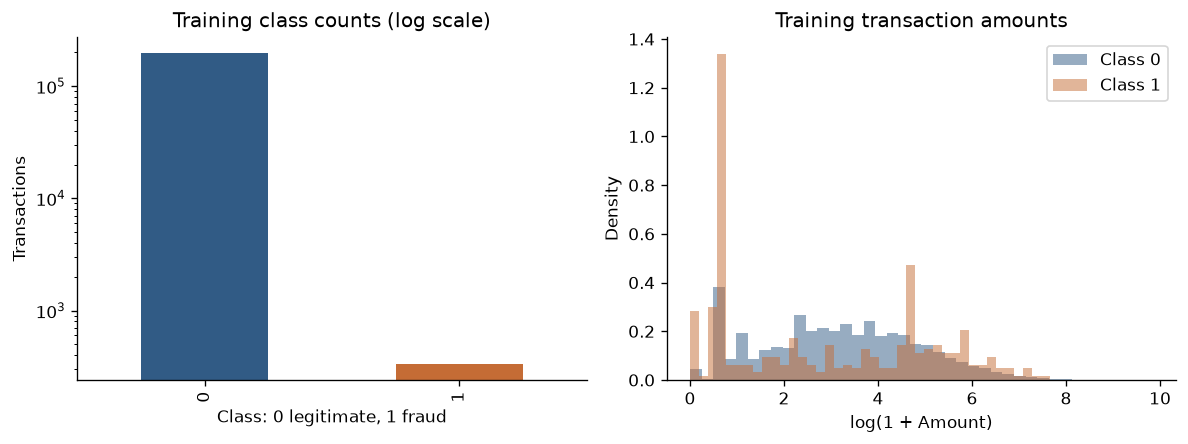

In [3]:
Xf = fraud.drop(columns='Class')
yf = fraud['Class']
Xf_train, Xf_test, yf_train, yf_test = train_test_split(
    Xf, yf, train_size=.7, test_size=.3, random_state=SEED, stratify=yf)
assert set(Xf_train.index).isdisjoint(Xf_test.index)
print('Train:', Xf_train.shape, 'Test:', Xf_test.shape)
display(pd.DataFrame({'train': yf_train.value_counts(), 'test': yf_test.value_counts()}).sort_index())
display(Xf_train[['Time', 'Amount']].describe().round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
yf_train.value_counts().sort_index().plot.bar(ax=axes[0], color=['#315b85','#c56c35'])
axes[0].set(title='Training class counts (log scale)', xlabel='Class: 0 legitimate, 1 fraud', ylabel='Transactions', yscale='log')
for label, color in [(0, '#315b85'), (1, '#c56c35')]:
    axes[1].hist(np.log1p(Xf_train.loc[yf_train.eq(label), 'Amount']), bins=40,
                 density=True, alpha=.5, label=f'Class {label}', color=color)
axes[1].set(title='Training transaction amounts', xlabel='log(1 + Amount)', ylabel='Density')
axes[1].legend(); plt.tight_layout(); plt.show()

### Train logistic regression
I used a pipeline with median imputation, standardization, and logistic regression. The data had no missing values; imputation served as a safeguard. I kept the classification threshold at **0.5**.

I compared ordinary logistic regression with `class_weight='balanced'` to examine the trade-off between catching fraud and raising false alarms. A majority-class baseline predicted every transaction as legitimate.

In [4]:
fraud_models = {}
for name, weight in [('Logistic regression', None), ('Balanced logistic regression', 'balanced')]:
    model = Pipeline([('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
        ('model', LogisticRegression(C=1.0, solver='lbfgs', max_iter=2000,
                                     class_weight=weight, random_state=SEED))])
    with warnings.catch_warnings():
        warnings.simplefilter('error', ConvergenceWarning)
        model.fit(Xf_train, yf_train)
    fraud_models[name] = model
    print(name, 'iterations:', model.named_steps['model'].n_iter_.tolist())
fraud_models['Majority baseline'] = DummyClassifier(strategy='most_frequent').fit(Xf_train, yf_train)

Logistic regression iterations: [16]
Balanced logistic regression iterations: [38]


### Evaluate
I reported accuracy plus fraud **precision** (how many flagged transactions are fraud), **recall** (how much fraud is detected), and **F1**. ROC-AUC and average precision assess score rankings. Accuracy alone can be misleading because legitimate transactions dominate this dataset.

,accuracy,balanced_accuracy,precision,recall,F1,ROC_AUC,average_precision,TN,FP,FN,TP
model,,,,,,,,,,,
Logistic regression,0.99908,0.77808,0.84043,0.55634,0.66949,0.96468,0.70404,84961,15,63,79
Balanced logistic regression,0.97318,0.93032,0.05265,0.88732,0.09941,0.96633,0.68768,82709,2267,16,126
Majority baseline,0.99833,0.50000,0.00000,0.00000,0.00000,0.50000,0.00167,84976,0,142,0


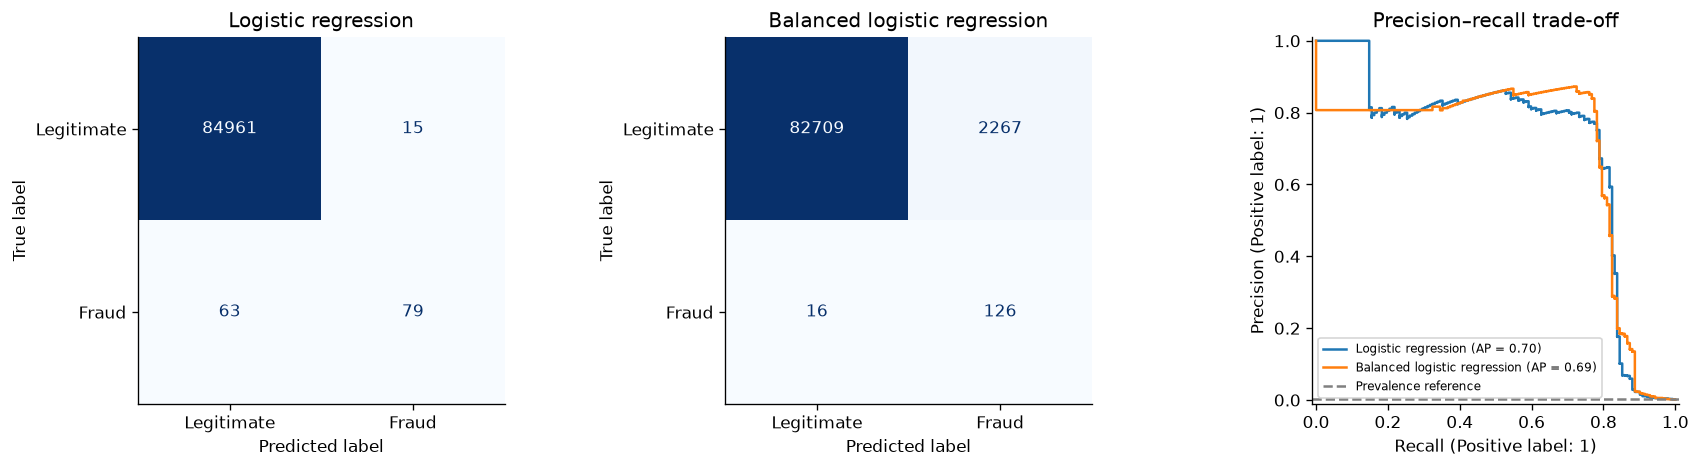

In [5]:
fraud_rows, fraud_predictions, fraud_scores = [], {}, {}
for name, model in fraud_models.items():
    pred = model.predict(Xf_test)
    scores = model.predict_proba(Xf_test)[:, 1]
    fraud_predictions[name], fraud_scores[name] = pred, scores
    tn, fp, fn, tp = confusion_matrix(yf_test, pred, labels=[0, 1]).ravel()
    fraud_rows.append({'model': name, 'accuracy': accuracy_score(yf_test, pred),
        'balanced_accuracy': balanced_accuracy_score(yf_test, pred),
        'precision': precision_score(yf_test, pred, zero_division=0),
        'recall': recall_score(yf_test, pred, zero_division=0),
        'F1': f1_score(yf_test, pred, zero_division=0),
        'ROC_AUC': roc_auc_score(yf_test, scores),
        'average_precision': average_precision_score(yf_test, scores),
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp})
fraud_metrics = pd.DataFrame(fraud_rows).set_index('model')
display(fraud_metrics.round(5))
fraud_metrics.to_csv(RESULTS/'fraud_metrics.csv')
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes[:2], list(fraud_models)[:2]):
    ConfusionMatrixDisplay.from_predictions(yf_test, fraud_predictions[name],
        display_labels=['Legitimate','Fraud'], colorbar=False, cmap='Blues', ax=ax)
    ax.set_title(name)
for name in list(fraud_models)[:2]:
    PrecisionRecallDisplay.from_predictions(yf_test, fraud_scores[name], name=name, ax=axes[2])
axes[2].axhline(yf_test.mean(), linestyle='--', color='gray', label='Prevalence reference')
axes[2].set_title('Precision–recall trade-off'); axes[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

In [6]:
ordinary = fraud_metrics.loc['Logistic regression']
balanced = fraud_metrics.loc['Balanced logistic regression']
display(Markdown(
    f"**Part A findings.** Ordinary logistic regression achieves **{ordinary['accuracy']:.3%} accuracy**, "
    f"**{ordinary['recall']:.2%} fraud recall**, and **{ordinary['precision']:.2%} precision**. "
    f"It detects {int(ordinary['TP'])} frauds, misses {int(ordinary['FN'])}, and flags "
    f"{int(ordinary['FP'])} legitimate transactions. Balanced logistic regression achieves "
    f"**{balanced['accuracy']:.3%} accuracy** and **{balanced['recall']:.2%} recall**, with "
    f"{int(balanced['FP'])} false positives. The majority baseline has "
    f"**{fraud_metrics.loc['Majority baseline','accuracy']:.3%} accuracy** but detects no fraud. "
    "Accuracy alone therefore does not establish an effective fraud detector."))
# Ordinary model is the primary demonstration; balanced model is a sensitivity comparison.
fraud_examples = Xf_test[['Time','Amount']].copy()
fraud_examples['actual'] = yf_test
fraud_examples['predicted'] = fraud_predictions['Logistic regression']
fraud_examples['fraud_score'] = fraud_scores['Logistic regression']
print('First 5 test rows (not selected for success):')
display(fraud_examples.head(5).round(4))
print('First 5 actual fraud rows — deliberately filtered to inspect fraud detection:')
display(fraud_examples.loc[fraud_examples['actual'].eq(1)].head(5).round(4))
fraud_examples.to_csv(RESULTS/'fraud_test_predictions.csv', index_label='source_row')

**Part A findings.** Ordinary logistic regression achieves **99.908% accuracy**, **55.63% fraud recall**, and **84.04% precision**. It detects 79 frauds, misses 63, and flags 15 legitimate transactions. Balanced logistic regression achieves **97.318% accuracy** and **88.73% recall**, with 2267 false positives. The majority baseline has **99.833% accuracy** but detects no fraud. Accuracy alone therefore does not establish an effective fraud detector.

First 5 test rows (not selected for success):


,Time,Amount,actual,predicted,fraud_score
139330,83104.0,19.45,0,0,0.0001
86361,61199.0,31.35,0,0,0.0002
94117,64741.0,0.89,0,0,0.0001
123803,77071.0,83.50,0,0,0.0001
126884,78136.0,250.00,0,0,0.0003


First 5 actual fraud rows — deliberately filtered to inspect fraud detection:


,Time,Amount,actual,predicted,fraud_score
72757,54846.0,1.79,1,0,0.0000
48094,43494.0,24.90,1,0,0.0226
201601,133958.0,130.21,1,0,0.3860
178208,123525.0,45.51,1,1,0.9990
231978,146998.0,8.00,1,0,0.0557


**My takeaway:** Ordinary logistic regression produced fewer false alarms, while class weighting detected more fraud. The better choice depends on the cost of missed fraud versus investigating legitimate transactions. I did not tune either model on test results. A random split also does not establish performance on future transactions.

## Part B — Insurance cost prediction
### Inspect and split
I predicted `charges` from age, sex, BMI, children, smoking category, and region. I checked missing values and ranges, removed the one exact duplicate, and split the data 70/30. I retained expensive cases because predicting them was part of the task.

In [7]:
insurance_raw = pd.read_csv(DATA/'insurance.csv')
print('Original dimensions:', insurance_raw.shape)
display(insurance_raw.head())
display(pd.DataFrame({'dtype': insurance_raw.dtypes.astype(str),
                      'missing': insurance_raw.isna().sum()}))
print('Exact duplicate rows:', insurance_raw.duplicated().sum())
insurance = insurance_raw.drop_duplicates().copy()
assert insurance['charges'].notna().all()
assert insurance['charges'].ge(0).all()
assert insurance['age'].ge(0).all() and insurance['bmi'].gt(0).all()
assert insurance['children'].ge(0).all()
for col in ['sex', 'smoker', 'region']:
    print(col, sorted(insurance[col].dropna().unique()))
Xi, yi = insurance.drop(columns='charges'), insurance['charges']
Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    Xi, yi, train_size=.7, test_size=.3, random_state=SEED)
assert set(Xi_train.index).isdisjoint(Xi_test.index)
print('Rows after deduplication:', len(insurance))
print('Train:', Xi_train.shape, 'Test:', Xi_test.shape)

Original dimensions: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


,dtype,missing
age,int64,0
sex,str,0
bmi,float64,0
children,int64,0
smoker,str,0
region,str,0
charges,float64,0


Exact duplicate rows: 1
sex ['female', 'male']
smoker ['no', 'yes']
region ['northeast', 'northwest', 'southeast', 'southwest']
Rows after deduplication: 1337
Train: (935, 6) Test: (402, 6)


### Explore training data
I compared charges by smoking category and plotted BMI against charges. These patterns describe associations, not causal effects.

,age,bmi,children,charges
count,935.00,935.00,935.00,935.00
mean,39.01,30.62,1.08,13035.07
std,14.00,6.02,1.20,11659.16
min,18.00,15.96,0.00,1121.87
25%,27.00,26.30,0.00,4718.86
50%,39.00,30.21,1.00,9283.56
75%,51.00,34.64,2.00,16830.61
max,64.00,53.13,5.00,58571.07


,count,mean,median
smoker,,,
no,741,8407.91,7261.74
yes,194,30708.90,31745.27


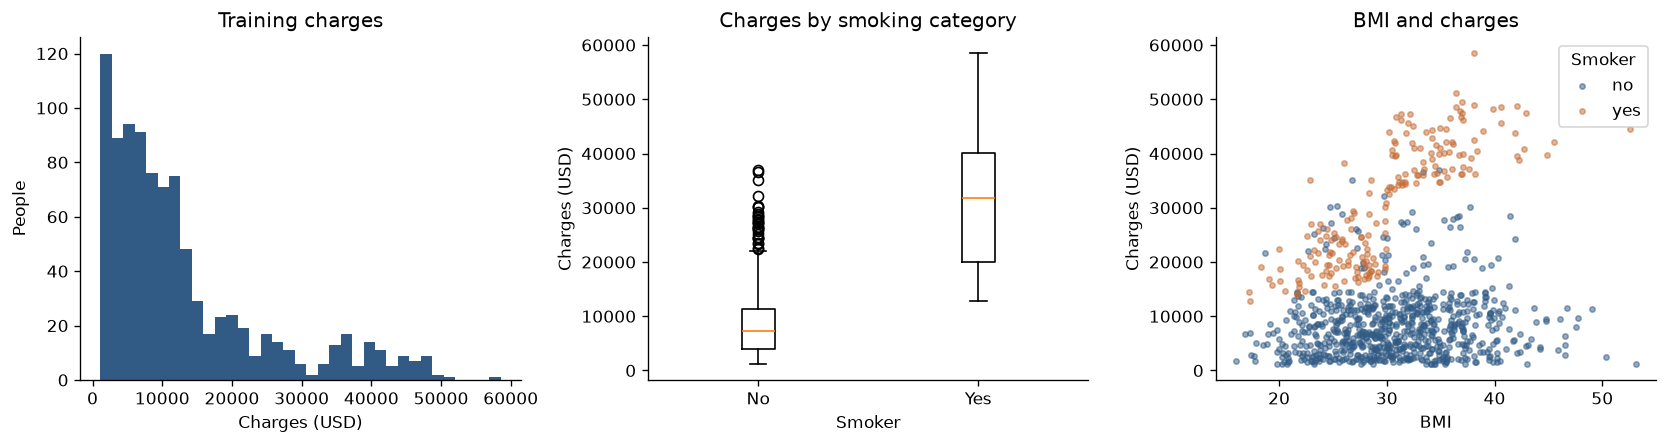

In [8]:
insurance_train = Xi_train.assign(charges=yi_train)
display(insurance_train.describe().round(2))
display(insurance_train.groupby('smoker')['charges'].agg(['count','mean','median']).round(2))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].hist(yi_train, bins=35, color='#315b85')
axes[0].set(title='Training charges', xlabel='Charges (USD)', ylabel='People')
axes[1].boxplot([yi_train[Xi_train['smoker'].eq(s)] for s in ['no','yes']], tick_labels=['No','Yes'])
axes[1].set(title='Charges by smoking category', xlabel='Smoker', ylabel='Charges (USD)')
for smoker, color in [('no','#315b85'),('yes','#c56c35')]:
    subset = insurance_train.loc[insurance_train['smoker'].eq(smoker)]
    axes[2].scatter(subset['bmi'],subset['charges'], s=10, alpha=.5, label=smoker, color=color)
axes[2].set(title='BMI and charges', xlabel='BMI', ylabel='Charges (USD)')
axes[2].legend(title='Smoker'); plt.tight_layout(); plt.show()

### Train linear regression
I imputed numeric values with training medians and categorical values with training modes. One-hot encoding used a reference category for each categorical predictor. The pipeline fitted preprocessing only on training data.

I fitted an additive linear regression and compared it with a baseline that always predicted the training mean. Coefficients describe changes in predicted dollars, holding other included predictors fixed; they are not causal effects.

In [9]:
numeric_cols = ['age','bmi','children']
categorical_cols = ['sex','smoker','region']
numeric_pipeline = Pipeline([('impute', SimpleImputer(strategy='median'))])
category_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OneHotEncoder(drop='first', handle_unknown='ignore'))])
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_cols),
    ('categorical', category_pipeline, categorical_cols)])
insurance_model = Pipeline([('preprocess', preprocessor), ('model', LinearRegression())])
insurance_model.fit(Xi_train, yi_train)
insurance_baseline = DummyRegressor(strategy='mean').fit(Xi_train, yi_train)
feature_names = insurance_model.named_steps['preprocess'].get_feature_names_out()
coefficients = pd.Series(insurance_model.named_steps['model'].coef_, index=feature_names,
                         name='coefficient_USD')
print('Intercept:', round(insurance_model.named_steps['model'].intercept_, 2))
display(coefficients.round(2).to_frame())
encoder = insurance_model.named_steps['preprocess'].named_transformers_['categorical'].named_steps['encode']
print('Reference categories:', dict(zip(categorical_cols, [v[0] for v in encoder.categories_])))
coefficients.to_csv(RESULTS/'insurance_coefficients.csv')

Intercept: -11516.78


,coefficient_USD
numeric__age,251.25
numeric__bmi,328.38
numeric__children,522.16
categorical__sex_male,-111.91
categorical__smoker_yes,22874.45
categorical__region_northwest,-465.75
categorical__region_southeast,-936.10
categorical__region_southwest,-765.58


Reference categories: {'sex': 'female', 'smoker': 'no', 'region': 'northeast'}


### Evaluate
For continuous costs, I used **R²**, **MAE**, and **RMSE**, rather than classification accuracy. R² measures improvement over predicting the test mean; MAE is the average absolute dollar error, and RMSE gives greater weight to large errors. I compared training and test scores and inspected residuals.

R2   MAE_USD   RMSE_USD
model                  split                            
Linear regression      Train  0.736  4165.831   5984.391
                       Test   0.772  4181.816   6240.206
Training-mean baseline Train  0.000  8823.443  11652.927
                       Test  -0.004  9423.657  13106.356

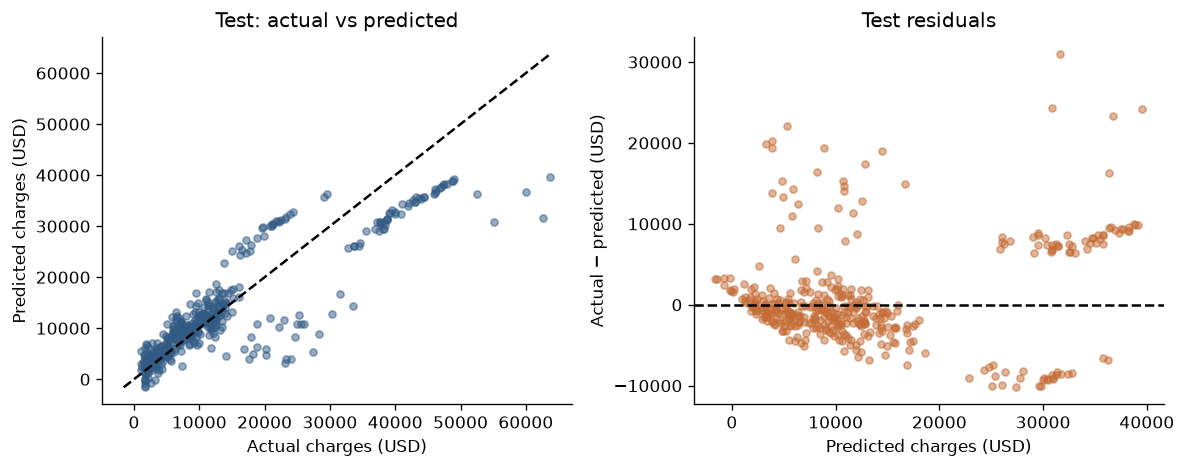

Negative test predictions: 7


In [10]:
insurance_rows = []
for name, model in [('Linear regression', insurance_model), ('Training-mean baseline', insurance_baseline)]:
    for split, x, y in [('Train', Xi_train, yi_train), ('Test', Xi_test, yi_test)]:
        predicted = model.predict(x)
        insurance_rows.append({'model': name, 'split': split, 'R2': r2_score(y,predicted),
            'MAE_USD': mean_absolute_error(y,predicted),
            'RMSE_USD': np.sqrt(mean_squared_error(y,predicted))})
insurance_metrics = pd.DataFrame(insurance_rows).set_index(['model','split'])
display(insurance_metrics.round(3))
insurance_metrics.to_csv(RESULTS/'insurance_metrics.csv')
insurance_pred = insurance_model.predict(Xi_test)
residuals = yi_test.to_numpy() - insurance_pred
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(yi_test,insurance_pred,alpha=.5,s=18,color='#315b85')
lo=min(yi_test.min(),insurance_pred.min()); hi=max(yi_test.max(),insurance_pred.max())
axes[0].plot([lo,hi],[lo,hi],'--',color='black')
axes[0].set(title='Test: actual vs predicted', xlabel='Actual charges (USD)', ylabel='Predicted charges (USD)')
axes[1].scatter(insurance_pred,residuals,alpha=.5,s=18,color='#c56c35')
axes[1].axhline(0,linestyle='--',color='black')
axes[1].set(title='Test residuals', xlabel='Predicted charges (USD)', ylabel='Actual − predicted (USD)')
plt.tight_layout(); plt.show()
print('Negative test predictions:', int((insurance_pred<0).sum()))

In [11]:
test_result = insurance_metrics.loc[('Linear regression','Test')]
baseline_result = insurance_metrics.loc[('Training-mean baseline','Test')]
display(Markdown(
    f"**Part B findings.** Test **R² = {test_result['R2']:.4f}**, "
    f"**MAE = ${test_result['MAE_USD']:,.2f}**, and **RMSE = ${test_result['RMSE_USD']:,.2f}**. "
    f"The mean baseline has MAE **${baseline_result['MAE_USD']:,.2f}** and "
    f"RMSE **${baseline_result['RMSE_USD']:,.2f}**. "
    "MAE describes the average absolute prediction error, not a guarantee for an individual person."))
insurance_examples = Xi_test.copy()
insurance_examples['actual_charges'] = yi_test
insurance_examples['predicted_charges'] = insurance_pred
insurance_examples['absolute_error'] = np.abs(residuals)
display(insurance_examples.head(5).round(2))
insurance_examples.to_csv(RESULTS/'insurance_test_predictions.csv', index_label='source_row')
print('Test error by smoking category:')
display(insurance_examples.groupby('smoker').agg(n=('absolute_error','size'),
    MAE_USD=('absolute_error','mean')).round(2))
# Reusable prediction function: input columns must follow the training schema.
def predict_insurance_cost(new_people):
    required = numeric_cols + categorical_cols
    missing = set(required) - set(new_people.columns)
    if missing:
        raise ValueError(f'Missing required input columns: {sorted(missing)}')
    return pd.Series(insurance_model.predict(new_people[required]),
                     index=new_people.index, name='predicted_charges')
print('Predictive-system demonstration using three held-out people:')
display(predict_insurance_cost(Xi_test.head(3)).round(2))
assert np.allclose(predict_insurance_cost(Xi_test.head(3)), insurance_pred[:3])

**Part B findings.** Test **R² = 0.7724**, **MAE = $4,181.82**, and **RMSE = $6,240.21**. The mean baseline has MAE **$9,423.66** and RMSE **$13,106.36**. MAE describes the average absolute prediction error, not a guarantee for an individual person.

,age,sex,bmi,children,smoker,region,actual_charges,predicted_charges,absolute_error
900,49,male,22.52,0,no,northeast,8688.86,8075.92,612.94
1064,29,female,25.60,4,no,southwest,5708.87,5499.00,209.86
1256,51,female,36.38,3,no,northwest,11436.74,14345.71,2908.97
298,31,male,34.39,3,yes,northwest,38746.36,31428.20,7318.15
237,31,male,38.39,2,no,southeast,4463.21,8874.78,4411.58


Test error by smoking category:


,n,MAE_USD
smoker,,
no,322,2913.58
yes,80,9286.47


Predictive-system demonstration using three held-out people:


900      8075.92
1064     5499.00
1256    14345.71
Name: predicted_charges, dtype: float64

## My conclusions
- **Fraud:** High accuracy does not guarantee good fraud detection. The balanced model improved recall but created many more false alarms.
- **Insurance:** Linear regression improved substantially on the mean baseline, but large residuals showed that the additive model missed some cost patterns. Its predictions can also be negative; I reported raw predictions without clipping.

These findings came from one fixed split. I would use training-only validation to explore fraud thresholds and insurance interaction terms before testing on new data.